## Section 1 - Introduction
1. Installing the necessary packages/dependencies
2. Load and normalize the CIFAR10 training and test datasets

In [3]:
import torch
import torchvision
from torchvision.transforms import v2

In [6]:
# Downloading the CIFAR10 dataset from HuggingFace as the download was slow (~80kB/s)

!pip install huggingface_hub
from huggingface_hub import login
HF_SECRET_NAME = "test"

from huggingface_hub import snapshot_download
snapshot_download(
   repo_id="uoft-cs/cifar10",
   repo_type="dataset",
   cache_dir="/kaggle/working",
   local_dir_use_symlinks=False,
   resume_download=True
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

'/kaggle/working/datasets--uoft-cs--cifar10/snapshots/0b2714987fa478483af9968de7c934580d0bb9a2'

In [7]:
import glob, io
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision.transforms import v2

# Same transform as the original cell
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

# Locate the parquet files that snapshot_download saved
def find_parquet(split):
    files = glob.glob(f"/kaggle/working/**/{split}-*.parquet", recursive=True)
    assert files, f"No {split} parquet found under /kaggle/working"
    return files[0]

class HFCIFAR10(Dataset):
    """Drop-in replacement for torchvision.datasets.CIFAR10 using HF parquet files."""
    def __init__(self, parquet_path, transform=None):
        df = pd.read_parquet(parquet_path)
        self.images = df["img"].tolist()      # dicts with 'bytes' (PNG data)
        self.labels = df["label"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = Image.open(io.BytesIO(self.images[idx]["bytes"])).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

trainset = HFCIFAR10(find_parquet("train"), transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = HFCIFAR10(find_parquet("test"), transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# Sanity check
print(len(trainset), len(testset))          # expect 50000 10000
images, labels = next(iter(trainloader))
print(images.shape, images.dtype, labels)   # expect torch.Size([4, 3, 32, 32]), float32
print(images.min().item(), images.max().item())  # roughly within [-1, 1]

50000 10000
torch.Size([4, 3, 32, 32]) torch.float32 tensor([4, 7, 6, 5])
-1.0 1.0


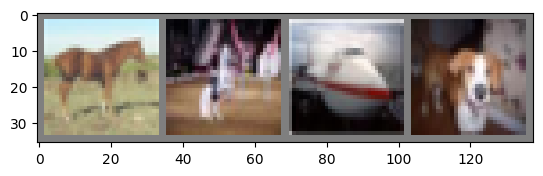

horse horse plane dog  


In [8]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image


def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

## Section 2 - Defining a CNN

In [9]:
import torch.nn as nn
import torch.nn.functional as F

# creating a neural network with multiple convolutional layers + fully connected layers
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 12, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(12, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net = Net()

In [11]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [12]:
import torch

def evaluate(net, loader, criterion):
    """Returns (avg loss, accuracy %) over a full dataloader."""
    was_training = net.training      # remember the mode so we can restore it
    net.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            outputs = net(inputs)
            # criterion returns a batch mean, so weight by batch size (last batch may be smaller)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    net.train(was_training)
    return total_loss / total, 100 * correct / total

In [13]:
for epoch in range(4):  # loop over the dataset multiple times

    running_loss = 0.0
    running_correct, running_total = 0, 0   # accuracy over the print window
    epoch_loss, epoch_correct, epoch_total = 0.0, 0, 0

    for i, data in enumerate(trainloader, 0):
        inputs, labels = data

        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # accuracy for this mini-batch
        preds = outputs.argmax(dim=1)
        batch_correct = (preds == labels).sum().item()

        # accumulate statistics
        running_loss += loss.item()
        running_correct += batch_correct
        running_total += labels.size(0)

        epoch_loss += loss.item() * labels.size(0)
        epoch_correct += batch_correct
        epoch_total += labels.size(0)

        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] '
                  f'loss: {running_loss / 2000:.3f}  '
                  f'acc: {100 * running_correct / running_total:.2f}%')
            running_loss = 0.0
            running_correct, running_total = 0, 0

    # end-of-epoch summary
    train_loss = epoch_loss / epoch_total
    train_acc = 100 * epoch_correct / epoch_total
    test_loss, test_acc = evaluate(net, testloader, criterion)
    print(f'--- Epoch {epoch + 1}: '
          f'train loss {train_loss:.3f}, train acc {train_acc:.2f}% | '
          f'test loss {test_loss:.3f}, test acc {test_acc:.2f}% ---')

print('Finished Training')

[1,  2000] loss: 2.197  acc: 17.34%
[1,  4000] loss: 1.812  acc: 32.30%
[1,  6000] loss: 1.630  acc: 39.99%
[1,  8000] loss: 1.526  acc: 43.79%
[1, 10000] loss: 1.472  acc: 45.99%
[1, 12000] loss: 1.440  acc: 48.05%
--- Epoch 1: train loss 1.669, train acc 38.37% | test loss 1.394, test acc 48.72% ---
[2,  2000] loss: 1.379  acc: 49.96%
[2,  4000] loss: 1.349  acc: 51.73%
[2,  6000] loss: 1.318  acc: 52.41%
[2,  8000] loss: 1.281  acc: 55.27%
[2, 10000] loss: 1.283  acc: 53.89%
[2, 12000] loss: 1.257  acc: 55.05%
--- Epoch 2: train loss 1.311, train acc 53.09% | test loss 1.232, test acc 56.27% ---
[3,  2000] loss: 1.179  acc: 57.73%
[3,  4000] loss: 1.183  acc: 57.86%
[3,  6000] loss: 1.179  acc: 58.01%
[3,  8000] loss: 1.189  acc: 57.96%
[3, 10000] loss: 1.175  acc: 59.00%
[3, 12000] loss: 1.138  acc: 59.56%
--- Epoch 3: train loss 1.173, train acc 58.41% | test loss 1.171, test acc 58.09% ---
[4,  2000] loss: 1.080  acc: 62.11%
[4,  4000] loss: 1.085  acc: 61.31%
[4,  6000] loss: 1.

In [14]:
PATH = './cifar_net.pth'
torch.save(net.state_dict(), PATH)

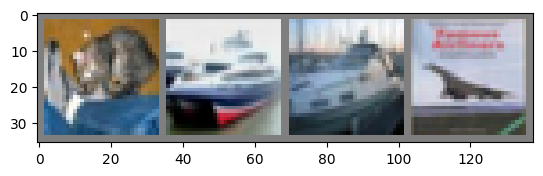

GroundTruth:  cat   ship  ship  plane


In [15]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

In [16]:
net = Net()
net.load_state_dict(torch.load(PATH, weights_only=True))
net.eval()

Net(
  (conv1): Conv2d(3, 12, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(12, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [17]:
outputs = net(images)

In [18]:
_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'
                              for j in range(4)))

Predicted:  cat   ship  car   plane


In [19]:
# same code path as the end-of-epoch test metric, so the numbers are directly comparable
test_loss, test_acc = evaluate(net, testloader, criterion)
print(f'Accuracy of the network on the {len(testset)} test images: {test_acc:.2f} %  (test loss {test_loss:.3f})')

Accuracy of the network on the 10000 test images: 60.67 %  (test loss 1.122)


In [21]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 70.9 %
Accuracy for class: car   is 80.5 %
Accuracy for class: bird  is 45.0 %
Accuracy for class: cat   is 48.1 %
Accuracy for class: deer  is 56.2 %
Accuracy for class: dog   is 41.9 %
Accuracy for class: frog  is 59.4 %
Accuracy for class: horse is 66.2 %
Accuracy for class: ship  is 78.9 %
Accuracy for class: truck is 59.6 %


In [22]:
device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')

# Assuming that we are on a CUDA machine, this should print a CUDA device:

print(device)

cuda


In [23]:
net.to(device)

Net(
  (conv1): Conv2d(3, 12, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(12, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [24]:
inputs, labels = data[0].to(device), data[1].to(device)